# DNN: a deep neural network

A DNN is a neural network with **many hidden layers**. This one has five (256, 128, 64, 32, 16 units), with batch normalisation and dropout in every block. Compare it with the ANN (one hidden layer) and the earlier MLP (three layers): if the extra depth does not help, that is a valid finding for your report.

**Feasibility:** fully feasible. It trains a bit slower than the ANN and is still fast at prediction time. Run after the preprocessing notebook. Everything is evaluated on the validation set.

## 1. Imports

In [1]:
# %pip install tensorflow matplotlib     # uncomment once if missing

import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
import keras
from keras import layers

print("keras", keras.__version__)

keras 3.15.1


## 2. Config

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

LEARNING_RATE = 1e-3
BATCH_SIZE = 512
EPOCHS = 60              # early stopping usually ends training much sooner
PATIENCE = 8

HIDDEN_UNITS = (256, 128, 64, 32, 16)   # five hidden layers
DROPOUT = 0.3

## 3. Load the processed data

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)
classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 4. Helpers (same evaluation as every other notebook)

In [5]:
def ms_per_1000(predict_fn, X, n=5000):
    """Prediction time in milliseconds per 1,000 flows (a model that is too slow cannot run live)."""
    Xs = X[:n]
    t0 = time.perf_counter()
    predict_fn(Xs)
    return round(1e6 * (time.perf_counter() - t0) / len(Xs), 1)


def report_binary(y_true, pred, title, score=None, ms=None):
    print(classification_report(y_true, pred, target_names=["Normal", "Attack"], digits=4))
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1)
    if score is not None:
        print(f"ROC-AUC:              {roc_auc_score(y_true, score):.4f}")
    print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
    print(f"False negative rate:  {fn / max(fn + tp, 1):.4f}  ({fn} attacks missed)")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
    ax.set_title(f"{title}: validation confusion matrix")
    plt.tight_layout()
    plt.show()
    return {"model": title,
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "false_pos_rate": fpr,
            "ms_per_1000_flows": ms}


def report_multiclass(y_true, pred, title, ms=None):
    labels = list(range(n_classes))
    print(classification_report(y_true, pred, labels=labels, target_names=class_names,
                                digits=4, zero_division=0))
    print("macro F1:    %.4f" % f1_score(y_true, pred, average="macro"))
    print("weighted F1: %.4f" % f1_score(y_true, pred, average="weighted"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
    axes[0].set_title("Counts")
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
    axes[1].set_title("Row-normalised (share of each true class)")
    plt.suptitle(f"{title}: validation confusion matrices")
    plt.tight_layout()
    plt.show()
    flagged = np.asarray(pred) != 0          # class 0 is Normal
    rows = []
    for i, name in enumerate(class_names):
        m = np.asarray(y_true) == i
        rows.append({"true class": name, "flows": int(m.sum()),
                     "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                     "correct type (%)": round(100 * (np.asarray(pred)[m] == i).mean(), 2)})
    display(pd.DataFrame(rows))
    return {"model": title + " (macro)",
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "f1": f1_score(y_true, pred, average="macro"),
            "false_pos_rate": np.nan,
            "ms_per_1000_flows": ms}

In [6]:
keras.utils.set_random_seed(SEED)


def head(x, n_out, binary):
    if binary:
        return layers.Dense(1, activation="sigmoid")(x)
    return layers.Dense(n_out, activation="softmax")(x)


def compile_model(model, binary):
    if binary:
        loss, metrics = "binary_crossentropy", [keras.metrics.AUC(name="auc")]
    else:
        loss, metrics = "sparse_categorical_crossentropy", ["accuracy"]
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=loss, metrics=metrics)
    return model


def fit_model(model, X_tr, y_tr, X_va, y_va, class_weight):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ]
    t0 = time.time()
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS,
                     batch_size=BATCH_SIZE, class_weight=class_weight,
                     callbacks=callbacks, verbose=2)
    print(f"trained {len(hist.history['loss'])} epochs in {time.time() - t0:.1f}s")
    return hist


def plot_history(hist, metric, title):
    h = hist.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="train")
    axes[0].plot(h["val_loss"], label="validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h[metric], label="train")
    axes[1].plot(h["val_" + metric], label="validation")
    axes[1].set_title(metric.upper()); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

## 5. Architecture

Each hidden block is Dense, BatchNorm, ReLU, Dropout. The output layer is 1 sigmoid unit for binary, or one softmax unit per class for multiclass.

In [7]:
def build_model(n_in, n_out, binary):
    inputs = keras.Input(shape=(n_in,))
    x = inputs
    for units in HIDDEN_UNITS:
        x = layers.Dense(units, use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(DROPOUT)(x)
    return keras.Model(inputs, head(x, n_out, binary))

## 6. Binary model (normal vs attack)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 39)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │         9,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 55,505 (216.82 KB)

 Trainable params: 54,513 (212.94 KB)

 Non-trainable params: 992 (3.88 KB)

Epoch 1/60
274/274 - 4s - 15ms/step - auc: 0.9277 - loss: 0.3433 - val_auc: 0.9840 - val_loss: 0.2062 - learning_rate: 0.0010
Epoch 2/60
274/274 - 2s - 7ms/step - auc: 0.9736 - loss: 0.2087 - val_auc: 0.9874 - val_loss: 0.1457 - learning_rate: 0.0010
Epoch 3/60
274/274 - 2s - 6ms/step - auc: 0.9785 - loss: 0.1853 - val_auc: 0.9882 - val_loss: 0.1451 - learning_rate: 0.0010
Epoch 4/60
274/274 - 2s - 6ms/step - auc: 0.9808 - loss: 0.1737 - val_auc: 0.9889 - val_loss: 0.1489 - learning_rate: 0.0010
Epoch 5/60
274/274 - 2s - 6ms/step - auc: 0.9824 - loss: 0.1658 - val_auc: 0.9896 - val_loss: 0.1306 - learning_rate: 0.0010
Epoch 6/60
274/274 - 2s - 6ms/step - auc: 0.9832 - loss: 0.1612 - val_auc: 0.9897 - val_loss: 0.1415 - learning_rate: 0.0010
Epoch 7/60
274/274 - 2s - 6ms/step - auc: 0.9840 - loss: 0.1574 - val_auc: 0.9904 - val_loss: 0.1255 - learning_rate: 0.0010
Epoch 8/60
274/274 - 2s - 6ms/step - auc: 0.9844 - loss: 0.1546 - val_auc: 0.9906 - val_loss: 0.1256 - learning_rate: 0.0010

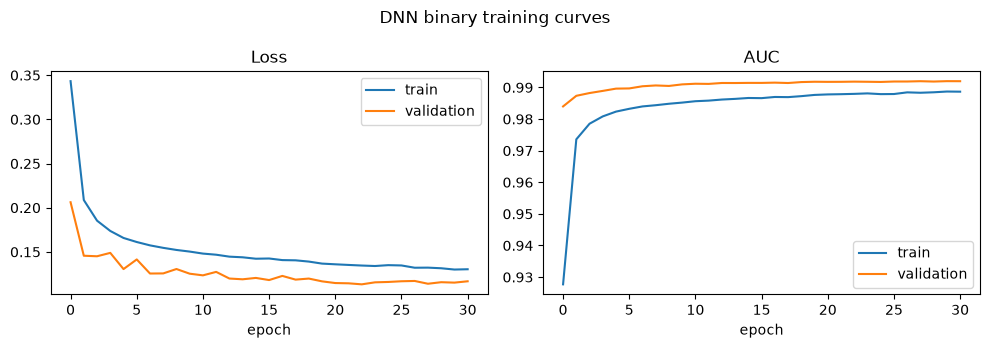

In [8]:
model_bin = compile_model(build_model(n_features, 1, True), True)
model_bin.summary()
hist_bin = fit_model(model_bin, X_train, yb_train, X_val, yb_val, cw_bin)
plot_history(hist_bin, "auc", "DNN binary training curves")

              precision    recall  f1-score   support

      Normal     0.8727    0.9576    0.9132     11200
      Attack     0.9791    0.9345    0.9563     23869

    accuracy                         0.9419     35069
   macro avg     0.9259    0.9460    0.9347     35069
weighted avg     0.9452    0.9419    0.9425     35069

ROC-AUC:              0.9921
False positive rate:  0.0424  (475 normal flows flagged as attacks)
False negative rate:  0.0655  (1564 attacks missed)


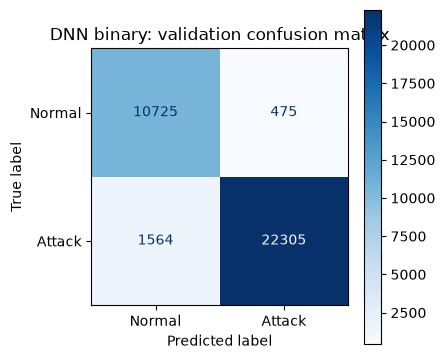

In [9]:
proba_bin = model_bin.predict(X_val, batch_size=4096, verbose=0).ravel()
pred_bin = (proba_bin >= 0.5).astype(int)
row_bin = report_binary(
    yb_val, pred_bin, "DNN binary", score=proba_bin,
    ms=ms_per_1000(lambda X: model_bin.predict(X, batch_size=4096, verbose=0), X_val))

## 7. Multiclass model

Epoch 1/60
274/274 - 4s - 13ms/step - accuracy: 0.5407 - loss: 1.4440 - val_accuracy: 0.6642 - val_loss: 0.9603 - learning_rate: 0.0010
Epoch 2/60
274/274 - 2s - 6ms/step - accuracy: 0.6657 - loss: 1.1395 - val_accuracy: 0.7459 - val_loss: 0.6651 - learning_rate: 0.0010
Epoch 3/60
274/274 - 2s - 6ms/step - accuracy: 0.6987 - loss: 1.0309 - val_accuracy: 0.7616 - val_loss: 0.6184 - learning_rate: 0.0010
Epoch 4/60
274/274 - 2s - 6ms/step - accuracy: 0.7090 - loss: 0.9777 - val_accuracy: 0.7674 - val_loss: 0.5988 - learning_rate: 0.0010
Epoch 5/60
274/274 - 2s - 6ms/step - accuracy: 0.7183 - loss: 0.9449 - val_accuracy: 0.7711 - val_loss: 0.5835 - learning_rate: 0.0010
Epoch 6/60
274/274 - 2s - 6ms/step - accuracy: 0.7236 - loss: 0.9193 - val_accuracy: 0.7761 - val_loss: 0.5789 - learning_rate: 0.0010
Epoch 7/60
274/274 - 2s - 6ms/step - accuracy: 0.7272 - loss: 0.9046 - val_accuracy: 0.7775 - val_loss: 0.5736 - learning_rate: 0.0010
Epoch 8/60
274/274 - 2s - 6ms/step - accuracy: 0.7289 

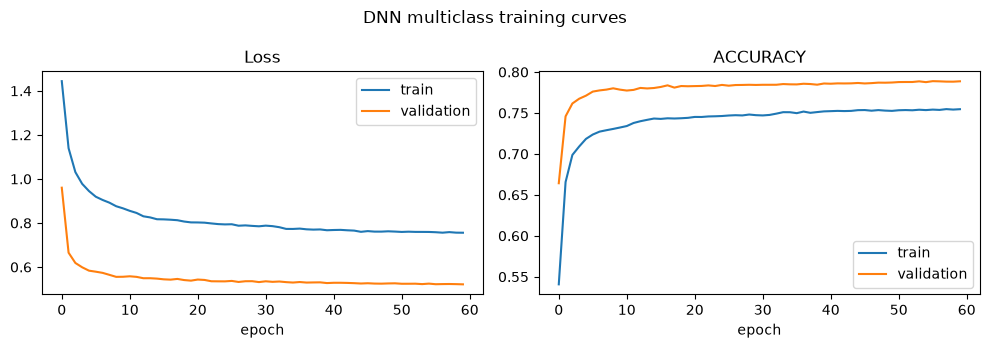

In [10]:
model_multi = compile_model(build_model(n_features, n_classes, False), False)
hist_multi = fit_model(model_multi, X_train, ym_train, X_val, ym_val, cw_multi)
plot_history(hist_multi, "accuracy", "DNN multiclass training curves")

                precision    recall  f1-score   support

        Normal     0.9993    0.8449    0.9156     11200
           DoS     0.3294    0.7986    0.4664      2453
Reconnaissance     0.7845    0.8118    0.7979      2099
       Fuzzers     0.6459    0.8606    0.7379      3637
      Exploits     0.8506    0.4816    0.6150      6678
       Generic     0.9996    0.9801    0.9898      8000
         Other     0.3409    0.3433    0.3421      1002

      accuracy                         0.7886     35069
     macro avg     0.7072    0.7316    0.6950     35069
  weighted avg     0.8559    0.7886    0.8020     35069

macro F1:    0.6950
weighted F1: 0.8020


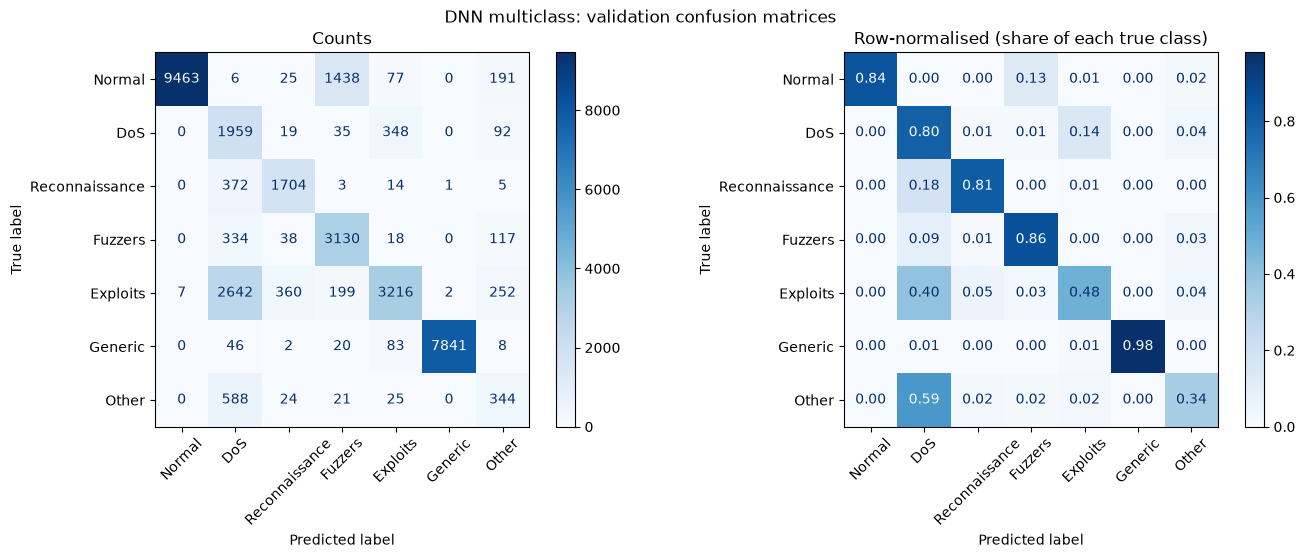

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,15.51,84.49
1,DoS,2453,100.00,79.86
2,Reconnaissance,2099,100.00,81.18
3,Fuzzers,3637,100.00,86.06
4,Exploits,6678,99.90,48.16
5,Generic,8000,100.00,98.01
6,Other,1002,100.00,34.33


In [11]:
pred_multi = model_multi.predict(X_val, batch_size=4096, verbose=0).argmax(axis=1)
row_multi = report_multiclass(
    ym_val, pred_multi, "DNN multiclass",
    ms=ms_per_1000(lambda X: model_multi.predict(X, batch_size=4096, verbose=0), X_val))

## 8. Save the models and compare with the other notebooks

The DNN is still small enough for live use. Compare `ms_per_1000_flows` against the ANN to see what the extra depth costs.

In [12]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)

model_bin.save(mdir / "dnn_binary.keras")
model_multi.save(mdir / "dnn_multiclass.keras")
pd.DataFrame([row_bin, row_multi]).to_csv(mdir / "dnn_validation_summary.csv", index=False)
for f in sorted(mdir.glob("dnn_*")):
    print(f"{f.name:32s} {f.stat().st_size / 1e3:9.1f} KB")

dnn_binary.keras                     751.9 KB
dnn_multiclass.keras                 752.9 KB
dnn_validation_summary.csv             0.2 KB


In [13]:
# compare with every other model whose notebook has been run
frames = [pd.read_csv(f) for f in sorted(Path(MODEL_DIR).glob("*_validation_summary.csv"))]
pd.concat(frames, ignore_index=True).round(4)

,model,precision,recall,f1,false_pos_rate,ms_per_1000_flows
0,Autoencoder binary,0.9666,0.6791,0.7977,0.0500,NaN
1,ANN binary,0.9763,0.9288,0.9520,0.0479,10.0
2,ANN multiclass (macro),0.7079,0.7254,0.6912,NaN,10.0
3,DNN binary,0.9791,0.9345,0.9563,0.0424,11.3
4,DNN multiclass (macro),0.7072,0.7316,0.6950,NaN,10.2
5,MLP binary,0.9800,0.9279,0.9532,0.0404,NaN
6,MLP multiclass (macro),0.7120,0.7350,0.6985,NaN,NaN
7,RF binary,0.9757,0.9610,0.9683,0.0511,NaN
8,RF multiclass (macro),0.6378,0.6286,0.6239,NaN,NaN
9,XGBoost binary,0.9823,0.9537,0.9678,0.0367,NaN
